In [12]:
%load_ext autoreload
%autoreload 2
import emcee
import corner
import pickle
import time
from astropy.table import QTable
from astropy import units as u
from astropy.nddata import NDData, StdDevUncertainty
from astropy import constants as const

import numpy as np
from matplotlib import pyplot as plt

import math
from decimal import Decimal


from nfw_profile_heating import NFWProfile
from statistics_functions import chi_squared

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
# import datasets
with open('data/mcxc_psz_combined.pkl', 'rb') as f:
    comb_data = pickle.load(f)
with open('data/REFLEX.p', 'rb') as g:
    errors_dict = pickle.load(g)

In [3]:
reflex_data = comb_data[comb_data['Sub-Cat']=='REFLEX']
reflex_appended = reflex_data.copy()
reflex_appended['L_err'] = reflex_appended['OName'].apply(lambda x: errors_dict.get(x))
reflex_clean = reflex_appended[reflex_appended['L_err'].notna()]
reflex_clean.head()

,MCXC,OName,AName,Ah Am RAs Ed Em Es,RAdeg DEdeg,GLON GLAT,z_x,Cat,Sub-Cat,Scale,...,E_MSZ,e_MSZ,RedMAPPer,ACT,SPT,ISE,AMIevi,O,Comment,L_err
1,J0003.1-0605,RXCJ0003.1-0605,A2697,0 3 11.8 - 6 5 10,0.799 -6.086,92.169 -66.033,0.2320,NORAS/REFLEX,REFLEX,3.698,...,0.368165,0.369144,RMJ000311.6-060530.1,,,-10,-1000.0,1,NaN,0.617909
2,J0003.8+0203,RXCJ0003.8+0203,A2700,0 3 50.6 + 2 3 48,0.961 2.063,99.610 -58.637,0.0924,NORAS/REFLEX,REFLEX,1.719,...,0.282160,0.301448,RMJ000349.7+020359.3,,,-10,-1000.0,0,NaN,0.147037
3,J0006.0-3443,RXCJ0006.0-3443,A2721,0 6 3.0 -34 43 27,1.513 -34.724,352.147 -77.668,0.1147,NORAS/REFLEX,REFLEX,2.080,...,0.248869,0.226974,,,,-10,-1000.0,1,NaN,0.227619
6,J0011.3-2851,RXCJ0011.3-2851,A2734,0 11 20.7 -28 51 18,2.836 -28.855,19.562 -80.986,0.0620,NORAS/REFLEX,REFLEX,1.195,...,0.182667,0.188038,,,,-10,-1000.0,1,NaN,0.092959
9,J0013.6-1930,RXCJ0013.6-1930,A0013,0 13 38.3 -19 30 8,3.409 -19.502,72.276 -78.456,0.0940,NORAS/REFLEX,REFLEX,1.746,...,0.233331,0.245311,,,,-10,-1000.0,1,NaN,0.133542


In [4]:
L_err_list = reflex_clean['L_err'].tolist()
variances = (np.array(L_err_list)*1e37*u.W).to(1e44*u.erg/u.s)

In [5]:
def generate_nfws_from_combined_dataset(dataset, nrows=None):
    cls_data={'M500':dataset['MSZ'],
          'L500':dataset['L500'],
          'z':dataset['z_y'] # take z from Planck
         }
    units={
        'M500': 1e14*u.Msun,
        'L500': 1e37*u.W,
        'z': None
    }

    cls_table=QTable(cls_data, units=units)
    
    n=nrows or len(cls_table)
    
    return [
        NFWProfile(
            cls_table['z'][i],
            M500=cls_table['M500'][i],
            L500=cls_table['L500'][i],
        )
        for i in range(n)
    ]

In [74]:
#TODO: update with mass
def log_lik(p0, obs, variances, nfws):
    log_s0 = p0[0]
    #mx = 1e-2*u.GeV
    log_mx = p0[1]
    # prior
    if log_s0>0 or log_s0<-40:
        return -np.inf
    if log_mx<-4 or 10**log_mx>const.m_p.to(u.GeV, equivalencies=u.mass_energy()).value:
        return -np.inf

    # calculate model predicted L500
    #base = np.array([10]).astype(object)
    #s0 = np.power(base.astype(object), log_s0.astype(object))*u.cm**2
    predicted = [nfw.L500_analytic(log_s0, log_mx) for nfw in nfws]
    X2 = chi_squared(predicted, obs, variances)
    #print(p0, -X2/2)
    return -X2/2

In [58]:
ncls = 10
nfws = generate_nfws_from_combined_dataset(reflex_clean[:ncls])
L_obs = [nfw.L500.to(u.erg/u.s) for nfw in nfws][:ncls]

In [59]:
nfws_subset = nfws[:ncls]
vars_subset = variances[:ncls]
obs_subset = L_obs[:ncls]

In [66]:
log_s0 = np.linspace(-50, -25, num=10)

In [69]:
log_liks2 = [log_lik([s, -2], obs_subset, vars_subset, nfws_subset) for s in log_s0]
log_liks4 = [log_lik([s, -4], obs_subset, vars_subset, nfws_subset) for s in log_s0]
log_liks1 = [log_lik([s, -1], obs_subset, vars_subset, nfws_subset) for s in log_s0]

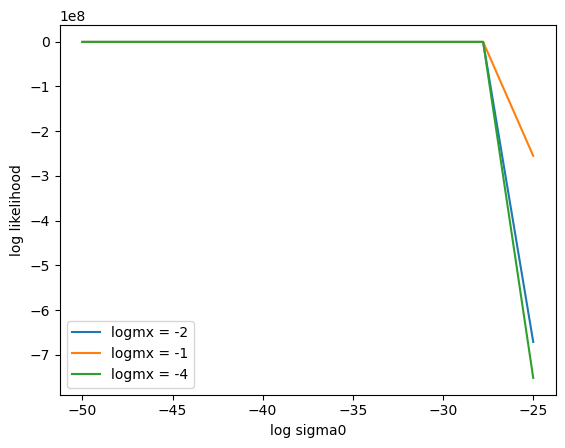

In [73]:
plt.plot(log_s0, log_liks2, label="logmx = -2")
plt.plot(log_s0, log_liks1, label="logmx = -1")
plt.plot(log_s0, log_liks4, label="logmx = -4")

plt.xlabel('log sigma0')
plt.ylabel('log likelihood')
plt.legend()

In [23]:
#ndim = 1
#nwalkers = 5
#nsteps = 1000
#initial = np.random.uniform(low=-50, high=-20, size=(nwalkers, ndim)).astype(np.float128)

#prepare MCMC
log_mp = np.log10(const.m_p.to(u.GeV, equivalencies=u.mass_energy()).value)

ndim, nwalkers = 2, 5
p0=np.zeros((nwalkers, ndim ))
log_sigma0 = np.random.uniform(low=-50, high=-20, size=nwalkers).astype(np.float128)
log_mx = np.random.uniform(low=-4, high=log_mp, size=nwalkers).astype(np.float128)
p0[:,0]=log_sigma0
p0[:,1]=log_mx
initial = p0
initial

array([[-31.91776495,  -1.76828398],
       [-36.09019639,  -3.81404381],
       [-35.45169368,  -1.55346388],
       [-40.91443216,  -2.90890218],
       [-40.0359352 ,  -0.07464822]])

In [24]:
nsteps = 100
sampler = emcee.EnsembleSampler(nwalkers,
                                ndim,
                                log_lik,
                                args=[obs_subset, vars_subset, nfws_subset])
start = time.time()
sampler.run_mcmc(initial, nsteps, progress=True)
end = time.time()
serial_time = end - start
print("Serial took {0:.1f} seconds".format(serial_time))

 39%|████████████████▍                         | 39/100 [02:06<04:29,  4.42s/it]Traceback (most recent call last):
  File "/Users/eleanorstuart/opt/anaconda3/envs/idm/lib/python3.11/site-packages/emcee/ensemble.py", line 624, in __call__
    return self.f(x, *self.args, **self.kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/var/folders/99/vfh56jrs1nqcj8zqtcs5fkv40000gn/T/ipykernel_29560/502012327.py", line 15, in log_lik
    predicted = [nfw.L500_analytic(log_s0, log_mx) for nfw in nfws]
                ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/var/folders/99/vfh56jrs1nqcj8zqtcs5fkv40000gn/T/ipykernel_29560/502012327.py", line 15, in <listcomp>
    predicted = [nfw.L500_analytic(log_s0, log_mx) for nfw in nfws]
                 ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/eleanorstuart/Desktop/krisp/thermo-idm/nfw_profile_heating.py", line 355, in L500_analytic
    net_cool = ((s0)*self.integrated_dm_cooling_rate(rmin, rmax, 1*u.cm**2, mx).to(u.e

emcee: Exception while calling your likelihood function:
  params: [-47.07769953  -1.81230598]
  args: [[<Quantity 6.107094e+44 erg / s>, <Quantity 8.46881e+43 erg / s>, <Quantity 1.809494e+44 erg / s>, <Quantity 1.086002e+44 erg / s>, <Quantity 1.236332e+44 erg / s>, <Quantity 2.827248e+44 erg / s>, <Quantity 1.1818114e+45 erg / s>, <Quantity 2.872451e+44 erg / s>, <Quantity 4.9467e+43 erg / s>, <Quantity 2.164603e+44 erg / s>], <Quantity [0.61790944, 0.1470371 , 0.22761947, 0.09295869, 0.1335421 ,
           0.3376997 , 1.72934127, 0.30620614, 0.04639702, 0.3303578 ] 1e+44 erg / s>, [<nfw_profile_heating.NFWProfile object at 0x12cd84cd0>, <nfw_profile_heating.NFWProfile object at 0x12e2b7c50>, <nfw_profile_heating.NFWProfile object at 0x12e7c1090>, <nfw_profile_heating.NFWProfile object at 0x12ca2f4d0>, <nfw_profile_heating.NFWProfile object at 0x12e73d510>, <nfw_profile_heating.NFWProfile object at 0x10e09b710>, <nfw_profile_heating.NFWProfile object at 0x10e0aa6d0>, <nfw_profile_he

KeyboardInterrupt: 

In [25]:
from multiprocessing import cpu_count

ncpu = cpu_count()
print("{0} CPUs".format(ncpu))

8 CPUs


In [77]:
from multiprocessing import Pool

with Pool() as pool:
    sampler = emcee.EnsembleSampler(nwalkers,
                                ndim,
                                log_lik,
                                args=[obs_subset, vars_subset, nfws_subset])
    start = time.time()
    state = sampler.run_mcmc(initial, nsteps, progress=True)
    end = time.time()
    multi_time = end - start
    print("Multiprocessing took {0:.1f} seconds".format(multi_time))
    #print("{0:.1f} times faster than serial".format(serial_time / multi_time))
    
    #nsteps = 100
    #sampler.run_mcmc(state, nsteps, progress = True)

100%|█████████████████████████████████████████| 100/100 [00:03<00:00, 25.40it/s]

Multiprocessing took 4.0 seconds


In [78]:
with Pool() as pool:
    sampler.run_mcmc(state, 1000, progress = True)

100%|███████████████████████████████████████| 1000/1000 [00:44<00:00, 22.61it/s]


In [79]:
with Pool() as pool:
    state = sampler.run_mcmc(state, 30000, progress = True)

100%|█████████████████████████████████████| 30000/30000 [21:39<00:00, 23.09it/s]


(155500, 2)


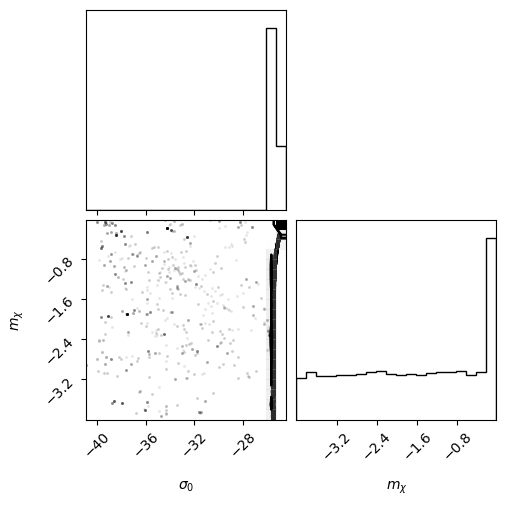

In [80]:
import matplotlib.pyplot as plt

#samples = sampler.get_chain(flat=True)
#plt.hist(samples[:, 0], 100, color="k", histtype="step")
#plt.xlabel(r"$\sigma_0$")
#plt.ylabel(r"$p(\sigma_0)$")
#plt.gca().set_yticks([]);

#flat_samples = sampler.get_chain(discard=100, thin=15, flat=True)
flat_samples = sampler.get_chain(flat=True)

print(flat_samples.shape)

import corner

labels = [r"$\sigma_0$", r"$m_\chi$"]
fig = corner.corner(
    flat_samples, labels=labels
);

In [81]:
print(
    "Mean acceptance fraction: {0:.3f}".format(
        np.mean(sampler.acceptance_fraction)
    )
)

Mean acceptance fraction: 0.404


In [82]:
print(
    "Mean autocorrelation time: {0:.3f} steps".format(
        np.mean(sampler.get_autocorr_time())
    )
)

AutocorrError: The chain is shorter than 50 times the integrated autocorrelation time for 2 parameter(s). Use this estimate with caution and run a longer chain!
N/50 = 622;
tau: [1048.96113519 1508.32162317]

In [73]:
np.median(samples)

-66.35362903211761

In [74]:
# with 10*Agn heating rate
with Pool() as pool:
    sampler2 = emcee.EnsembleSampler(nwalkers,
                                ndim,
                                log_lik,
                                args=[obs_subset, vars_subset, nfws_subset])
    start = time.time()
    state = sampler2.run_mcmc(initial, 1000, progress=True)
    end = time.time()
    multi_time = end - start
    print("Multiprocessing took {0:.1f} seconds".format(multi_time))
    print("{0:.1f} times faster than serial".format(serial_time / multi_time))
    
    nsteps = 10000
    sampler2.run_mcmc(state, nsteps, progress = True)

100%|█████████████████████████████████████| 10000/10000 [29:06<00:00,  5.73it/s]


Multiprocessing took 1746.7 seconds
0.0 times faster than serial


100%|█████████████████████████████████████| 10000/10000 [19:55<00:00,  8.36it/s]


(-28.0, -24.0)

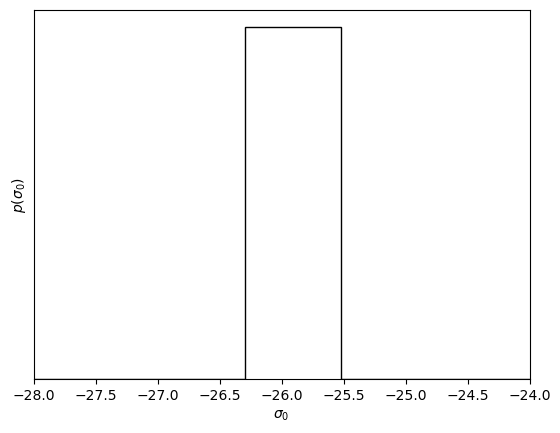

In [81]:
#plot after multiplying agn heating by 10

samples2 = sampler2.get_chain(flat=True)
plt.hist(samples2[:, 0], 100, color="k", histtype="step")
plt.xlabel(r"$\sigma_0$")
plt.ylabel(r"$p(\sigma_0)$")
plt.gca().set_yticks([]);
plt.xlim(-28,-24)

In [78]:
np.median(samples2)

-25.874611711596405

In [75]:
# with 1*iqbalagn
with Pool() as pool:
    sampler2 = emcee.EnsembleSampler(nwalkers,
                                ndim,
                                log_lik,
                                args=[obs_subset, vars_subset, nfws_subset])
    start = time.time()
    state2 = sampler2.run_mcmc(initial, 1000, progress=True)
    end = time.time()
    multi_time = end - start
    #print("Multiprocessing took {0:.1f} seconds".format(multi_time))
    #print("{0:.1f} times faster than serial".format(serial_time / multi_time))

    sampler2.run_mcmc(state2, 10000, progress = True)

  0%|                                                  | 0/1000 [00:00<?, ?it/s]/Users/eleanorstuart/opt/anaconda3/envs/idm/lib/python3.11/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|█████████████████████████████████████| 10000/10000 [06:41<00:00, 24.91it/s]


(55000, 2)


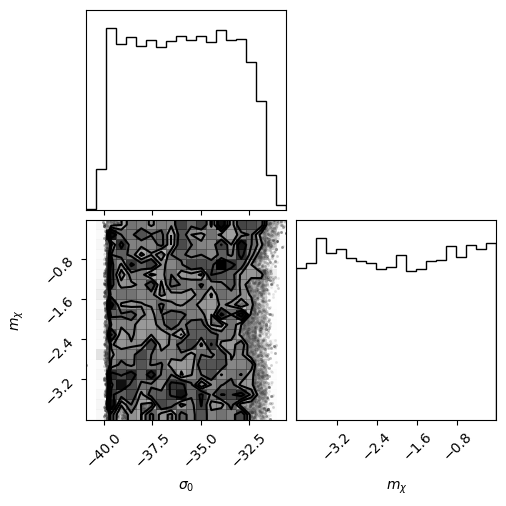

In [76]:
import matplotlib.pyplot as plt

#samples = sampler.get_chain(flat=True)
#plt.hist(samples[:, 0], 100, color="k", histtype="step")
#plt.xlabel(r"$\sigma_0$")
#plt.ylabel(r"$p(\sigma_0)$")
#plt.gca().set_yticks([]);

#flat_samples = sampler.get_chain(discard=100, thin=15, flat=True)
flat_samples2 = sampler2.get_chain(flat=True)

print(flat_samples2.shape)

import corner

labels = [r"$\sigma_0$", r"$m_\chi$"]
fig2 = corner.corner(
    flat_samples2, labels=labels
);

In [64]:
print(
    "Mean autocorrelation time: {0:.3f} steps".format(
        np.mean(sampler2.get_autocorr_time())
    )
)

Mean autocorrelation time: 64.451 steps
